In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

np.random.seed(42)

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


## Part A - Decision Tree from Scratch

In [2]:
# Select two features for decision-boundary visualization
X_2d = df[["variance", "skewness"]].values
y = df["class"].values

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_2d.shape)
print("Testing shape:", X_test_2d.shape)

Training shape: (1097, 2)
Testing shape: (275, 2)


In [3]:
def gini_impurity(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


# Test the functions
example_labels = np.array([0, 0, 1, 1])

print("Gini impurity:", gini_impurity(example_labels))
print("Entropy:", entropy(example_labels))

Gini impurity: 0.5
Entropy: 1.0


In [4]:
def best_split(X, y, criterion="gini"):
    n_samples, n_features = X.shape

    if n_samples <= 1:
        return None, None, None

    impurity_function = (
        gini_impurity if criterion == "gini" else entropy
    )

    parent_impurity = impurity_function(y)

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        thresholds = np.unique(X[:, feature])

        for threshold in thresholds[:-1]:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_impurity = (
                len(y_left) / n_samples * impurity_function(y_left)
                + len(y_right) / n_samples * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = (
                    threshold + thresholds[np.where(thresholds == threshold)[0][0] + 1]
                ) / 2

    if best_feature is None:
        return None, None, None

    return best_feature, best_threshold, best_gain

In [5]:
class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2
    ):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _majority_class(self, y):
        values, counts = np.unique(y, return_counts=True)
        return values[np.argmax(counts)]

    def _build_tree(self, X, y, depth):
        # Create the current node
        node = {
            "prediction": self._majority_class(y),
            "samples": len(y),
            "impurity": (
                gini_impurity(y)
                if self.criterion == "gini"
                else entropy(y)
            )
        }

        # Stopping conditions
        if (
            len(np.unique(y)) == 1
            or (
                self.max_depth is not None
                and depth >= self.max_depth
            )
            or len(y) < self.min_samples_split
        ):
            return node

        # Find the best split
        feature, threshold, gain = best_split(
            X, y, self.criterion
        )

        # Stop if no useful split is available
        if feature is None or gain <= 0:
            return node

        # Divide the samples into left and right groups
        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        # Store the split information
        node["feature"] = feature
        node["threshold"] = threshold
        node["gain"] = gain

        # Build child nodes recursively
        node["left"] = self._build_tree(
            X[left_mask],
            y[left_mask],
            depth + 1
        )

        node["right"] = self._build_tree(
            X[right_mask],
            y[right_mask],
            depth + 1
        )

        return node

    def fit(self, X, y):
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        # Leaf node: return its predicted class
        if "feature" not in node:
            return node["prediction"]

        # Follow the appropriate branch
        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])

        return self._predict_one(x, node["right"])

    def predict(self, X):
        return np.array([
            self._predict_one(x, self.root)
            for x in X
        ])

In [6]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5
)

start_time = time.perf_counter()
manual_tree.fit(X_train_2d, y_train_2d)
manual_tree_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
manual_tree_predictions = manual_tree.predict(X_test_2d)
manual_tree_prediction_time = time.perf_counter() - start_time

print("Manual Decision Tree")
print("Accuracy:", accuracy_score(y_test_2d, manual_tree_predictions))
print("Precision:", precision_score(y_test_2d, manual_tree_predictions, zero_division=0))
print("Recall:", recall_score(y_test_2d, manual_tree_predictions, zero_division=0))
print("F1-score:", f1_score(y_test_2d, manual_tree_predictions, zero_division=0))
print("Training time:", manual_tree_train_time)
print("Prediction time:", manual_tree_prediction_time)

Manual Decision Tree
Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059
Training time: 2.9327343000040855
Prediction time: 0.0012338999949861318


In [7]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start_time = time.perf_counter()
sklearn_tree.fit(X_train_2d, y_train_2d)
sklearn_tree_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_tree_predictions = sklearn_tree.predict(X_test_2d)
sklearn_tree_prediction_time = time.perf_counter() - start_time

print("Scikit-learn Decision Tree")
print("Accuracy:", accuracy_score(y_test_2d, sklearn_tree_predictions))
print("Precision:", precision_score(y_test_2d, sklearn_tree_predictions, zero_division=0))
print("Recall:", recall_score(y_test_2d, sklearn_tree_predictions, zero_division=0))
print("F1-score:", f1_score(y_test_2d, sklearn_tree_predictions, zero_division=0))
print("Training time:", sklearn_tree_train_time)
print("Prediction time:", sklearn_tree_prediction_time)

print(
    "Prediction agreement:",
    np.mean(manual_tree_predictions == sklearn_tree_predictions)
)

Scikit-learn Decision Tree
Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059
Training time: 0.012707300018519163
Prediction time: 0.0008793999732006341
Prediction agreement: 1.0


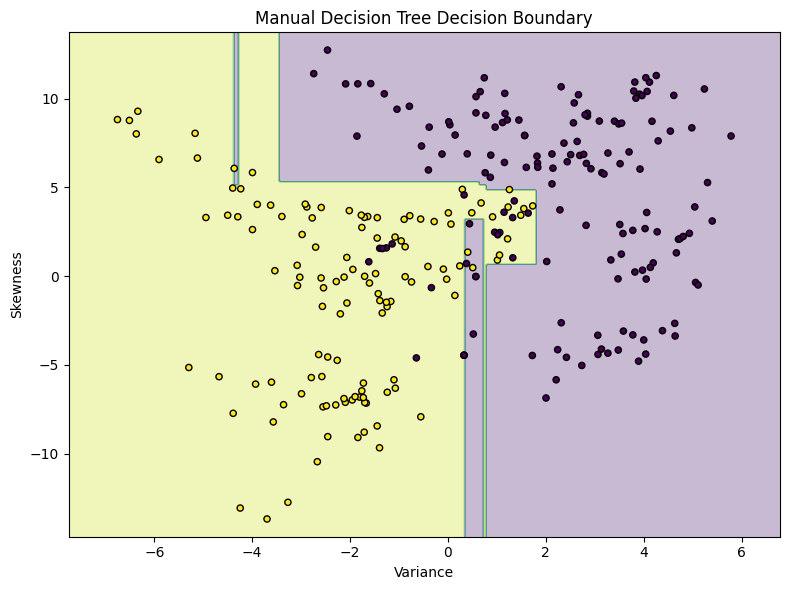

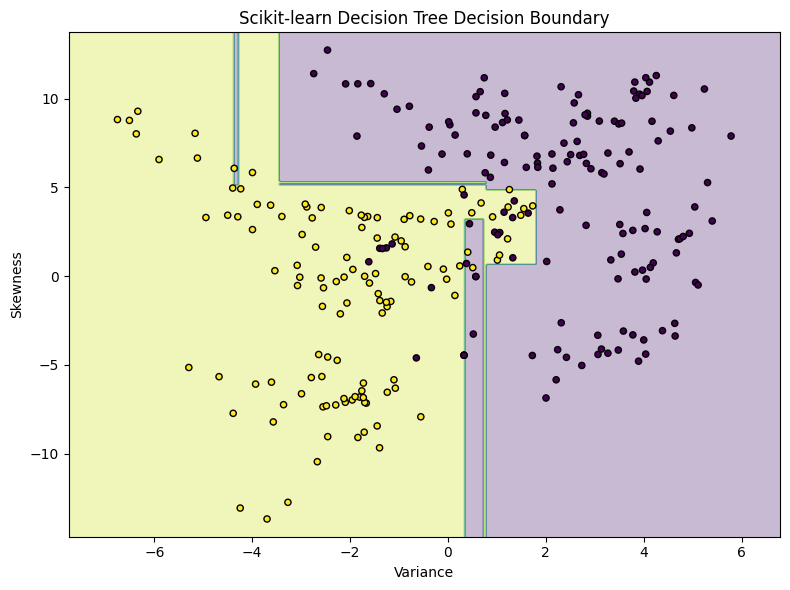

In [8]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, predictions, alpha=0.3)
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, edgecolors="black", s=20
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_decision_boundary(
    manual_tree, X_test_2d, y_test_2d,
    "Manual Decision Tree Decision Boundary"
)

plot_decision_boundary(
    sklearn_tree, X_test_2d, y_test_2d,
    "Scikit-learn Decision Tree Decision Boundary"
)

In [9]:
feature_names = ["variance", "skewness"]

def print_tree_rules(node, feature_names, indent=""):
    if "feature" not in node:
        print(indent + "Predict class:", node["prediction"])
        return

    feature_name = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}IF {feature_name} <= {threshold:.4f}")
    print_tree_rules(node["left"], feature_names, indent + "  ")

    print(f"{indent}ELSE ({feature_name} > {threshold:.4f})")
    print_tree_rules(node["right"], feature_names, indent + "  ")


print_tree_rules(manual_tree.root, feature_names)

IF variance <= 0.7651
  IF skewness <= 5.1608
    IF variance <= 0.3202
      IF variance <= -0.4586
        IF skewness <= 0.0548
          Predict class: 1
        ELSE (skewness > 0.0548)
          Predict class: 1
      ELSE (variance > -0.4586)
        IF skewness <= -0.1666
          Predict class: 1
        ELSE (skewness > -0.1666)
          Predict class: 1
    ELSE (variance > 0.3202)
      IF skewness <= 3.2197
        IF variance <= 0.7406
          Predict class: 0
        ELSE (variance > 0.7406)
          Predict class: 1
      ELSE (skewness > 3.2197)
        Predict class: 1
  ELSE (skewness > 5.1608)
    IF variance <= -3.4311
      IF variance <= -4.3819
        Predict class: 1
      ELSE (variance > -4.3819)
        IF variance <= -4.2554
          Predict class: 0
        ELSE (variance > -4.2554)
          Predict class: 1
    ELSE (variance > -3.4311)
      IF skewness <= 5.3646
        IF variance <= 0.6458
          Predict class: 1
        ELSE (variance > 0.

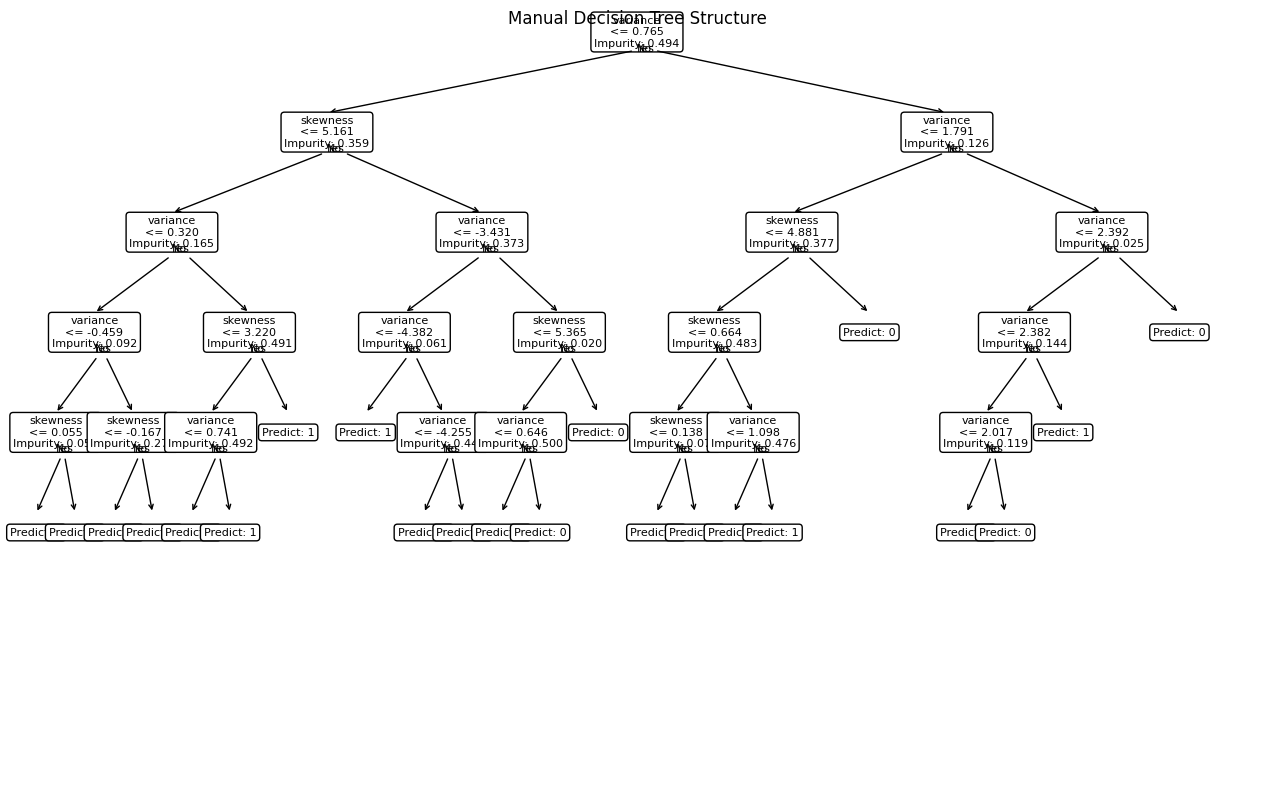

In [10]:
def draw_manual_tree(node, feature_names, ax, x=0.5, y=1.0,
                    dx=0.25, dy=0.13):
    if "feature" in node:
        label = (
            f"{feature_names[node['feature']]}\n"
            f"<= {node['threshold']:.3f}\n"
            f"Impurity: {node['impurity']:.3f}"
        )
    else:
        label = f"Predict: {node['prediction']}"

    ax.text(
        x, y, label,
        ha="center", va="center",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black"),
        fontsize=8,
        transform=ax.transAxes
    )

    if "feature" in node:
        children = [
            (node["left"], x - dx, "Yes"),
            (node["right"], x + dx, "No")
        ]

        for child, child_x, branch_label in children:
            child_y = y - dy

            ax.annotate(
                branch_label,
                xy=(child_x, child_y + 0.025),
                xytext=(x, y - 0.025),
                xycoords=ax.transAxes,
                textcoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->"),
                fontsize=8
            )

            draw_manual_tree(
                child, feature_names, ax,
                child_x, child_y, dx / 2, dy
            )


fig, ax = plt.subplots(figsize=(16, 10))
ax.axis("off")
draw_manual_tree(manual_tree.root, feature_names, ax)
plt.title("Manual Decision Tree Structure")
plt.show()

In [11]:
tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8, None]:
        model = ManualDecisionTree(
            criterion=criterion,
            max_depth=depth
        )

        start = time.perf_counter()
        model.fit(X_train_2d, y_train_2d)
        train_time = time.perf_counter() - start

        predictions = model.predict(X_test_2d)

        tree_results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test_2d, predictions),
            "Precision": precision_score(
                y_test_2d, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test_2d, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test_2d, predictions, zero_division=0
            ),
            "Training Time (s)": train_time
        })

tree_results_df = pd.DataFrame(tree_results)
display(tree_results_df.round(4))

,Criterion,Max Depth,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,gini,2,0.8764,0.8667,0.8525,0.8595,1.2224
1,gini,3,0.9091,0.8760,0.9262,0.9004,1.8635
2,gini,5,0.9309,0.8815,0.9754,0.9261,2.2467
3,gini,8,0.9164,0.8722,0.9508,0.9098,3.0337
4,gini,None,0.9200,0.8788,0.9508,0.9134,2.1530
5,entropy,2,0.8764,0.8667,0.8525,0.8595,0.6718
6,entropy,3,0.9091,0.8760,0.9262,0.9004,0.8580
7,entropy,5,0.9345,0.9000,0.9590,0.9286,1.0665
8,entropy,8,0.9273,0.8984,0.9426,0.9200,1.3691
9,entropy,None,0.9345,0.9062,0.9508,0.9280,1.3295


In [12]:
sklearn_tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8, None]:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        start = time.perf_counter()
        model.fit(X_train_2d, y_train_2d)
        train_time = time.perf_counter() - start

        predictions = model.predict(X_test_2d)

        sklearn_tree_results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test_2d, predictions),
            "F1-score": f1_score(
                y_test_2d, predictions, zero_division=0
            ),
            "Training Time (s)": train_time
        })

sklearn_tree_results_df = pd.DataFrame(sklearn_tree_results)
display(sklearn_tree_results_df.round(4))

,Criterion,Max Depth,Accuracy,F1-score,Training Time (s)
0,gini,2,0.8764,0.8595,0.0051
1,gini,3,0.9091,0.9004,0.0097
2,gini,5,0.9309,0.9261,0.0089
3,gini,8,0.9200,0.9141,0.0084
4,gini,None,0.9200,0.9134,0.0190
5,entropy,2,0.8764,0.8595,0.0030
6,entropy,3,0.9091,0.9004,0.0027
7,entropy,5,0.9345,0.9286,0.0057
8,entropy,8,0.9236,0.9157,0.0039
9,entropy,None,0.9345,0.9280,0.0049


## Part B - Linear SVM from Scratch

In [13]:
# Use the same two-feature dataset from Part A
X_train_svm = X_train_2d.copy()
X_test_svm = X_test_2d.copy()

y_train_svm = y_train_2d.copy()
y_test_svm = y_test_2d.copy()

# Scale using training data only
svm_scaler = StandardScaler()

X_train_svm_scaled = svm_scaler.fit_transform(X_train_svm)
X_test_svm_scaled = svm_scaler.transform(X_test_svm)

# Convert labels: original class 0 -> -1, class 1 -> +1
y_train_svm_signed = np.where(y_train_svm == 1, 1, -1)
y_test_svm_signed = np.where(y_test_svm == 1, 1, -1)

print("Training shape:", X_train_svm_scaled.shape)
print("Testing shape:", X_test_svm_scaled.shape)
print("Training labels:", np.unique(y_train_svm_signed))
print("Testing labels:", np.unique(y_test_svm_signed))

Training shape: (1097, 2)
Testing shape: (275, 2)
Training labels: [-1  1]
Testing labels: [-1  1]


In [14]:
class ManualLinearSVM:
    def __init__(
        self,
        C=1.0,
        learning_rate=0.001,
        n_iterations=5000
    ):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for iteration in range(self.n_iterations):
            # Signed distance score multiplied by true label
            margins = y * (X @ self.w + self.b)

            # Samples with margin < 1 contribute hinge loss
            violating = margins < 1

            # Gradient of regularization term
            dw = self.w.copy()
            db = 0.0

            # Add hinge-loss subgradient
            if np.any(violating):
                dw -= (
                    self.C / n_samples
                ) * (X[violating].T @ y[violating])

                db -= (
                    self.C / n_samples
                ) * np.sum(y[violating])

            # Gradient descent update
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            # Record objective value
            scores = X @ self.w + self.b
            hinge_losses = np.maximum(0, 1 - y * scores)

            loss = (
                0.5 * np.sum(self.w ** 2)
                + self.C * np.mean(hinge_losses)
            )

            self.loss_history.append(loss)

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(
            self.decision_function(X) >= 0,
            1,
            -1
        )

In [15]:
manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

start_time = time.perf_counter()
manual_svm.fit(X_train_svm_scaled, y_train_svm_signed)
manual_svm_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
manual_svm_predictions = manual_svm.predict(X_test_svm_scaled)
manual_svm_prediction_time = time.perf_counter() - start_time

print("Manual Linear SVM")
print("Accuracy:", accuracy_score(y_test_svm_signed, manual_svm_predictions))
print("Precision:", precision_score(y_test_svm_signed, manual_svm_predictions, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test_svm_signed, manual_svm_predictions, pos_label=1, zero_division=0))
print("F1-score:", f1_score(y_test_svm_signed, manual_svm_predictions, pos_label=1, zero_division=0))
print("Training time:", manual_svm_train_time)
print("Prediction time:", manual_svm_prediction_time)
print("Weights:", manual_svm.w)
print("Bias:", manual_svm.b)

Manual Linear SVM
Accuracy: 0.8654545454545455
Precision: 0.912621359223301
Recall: 0.7704918032786885
F1-score: 0.8355555555555556
Training time: 1.0794287999742664
Prediction time: 0.00015800000983290374
Weights: [-0.502542   -0.25609766]
Bias: -0.26505742935276694


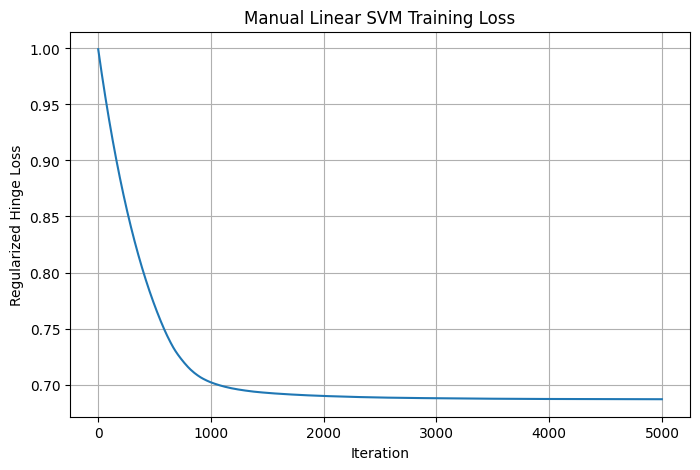

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(manual_svm.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Regularized Hinge Loss")
plt.title("Manual Linear SVM Training Loss")
plt.grid(True)
plt.show()

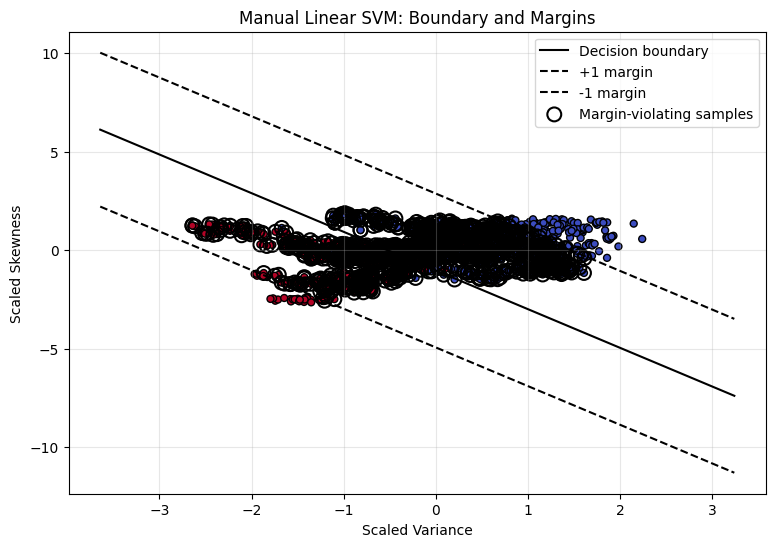

In [17]:
def plot_svm_boundary(model, X, y, title, show_violations=False):
    plt.figure(figsize=(9, 6))

    # Scatter the scaled data
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=25
    )

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x_values = np.linspace(x_min, x_max, 300)

    w = model.w
    b = model.b

    # Decision boundary and margin lines
    if abs(w[1]) > 1e-12:
        boundary = -(w[0] * x_values + b) / w[1]
        upper_margin = -(w[0] * x_values + b - 1) / w[1]
        lower_margin = -(w[0] * x_values + b + 1) / w[1]

        plt.plot(x_values, boundary, "k-", label="Decision boundary")
        plt.plot(x_values, upper_margin, "k--", label="+1 margin")
        plt.plot(x_values, lower_margin, "k--", label="-1 margin")

        if show_violations:
            scores = y * model.decision_function(X)
            violating = scores < 1

            plt.scatter(
                X[violating, 0], X[violating, 1],
                s=100, facecolors="none",
                edgecolors="black", linewidths=1.5,
                label="Margin-violating samples"
            )

    else:
        boundary_x = -b / w[0]
        plt.axvline(boundary_x, color="black", label="Decision boundary")
        plt.axvline(boundary_x + 1 / w[0], color="black", linestyle="--", label="Margins")
        plt.axvline(boundary_x - 1 / w[0], color="black", linestyle="--")

    plt.xlabel("Scaled Variance")
    plt.ylabel("Scaled Skewness")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


plot_svm_boundary(
    manual_svm,
    X_train_svm_scaled,
    y_train_svm_signed,
    "Manual Linear SVM: Boundary and Margins",
    show_violations=True
)

Scikit-learn Linear SVM
Accuracy: 0.8763636363636363
Precision: 0.8492063492063492
Recall: 0.8770491803278688
F1-score: 0.8629032258064516
Training time: 0.03331239998806268
Prediction time: 0.004428900021594018


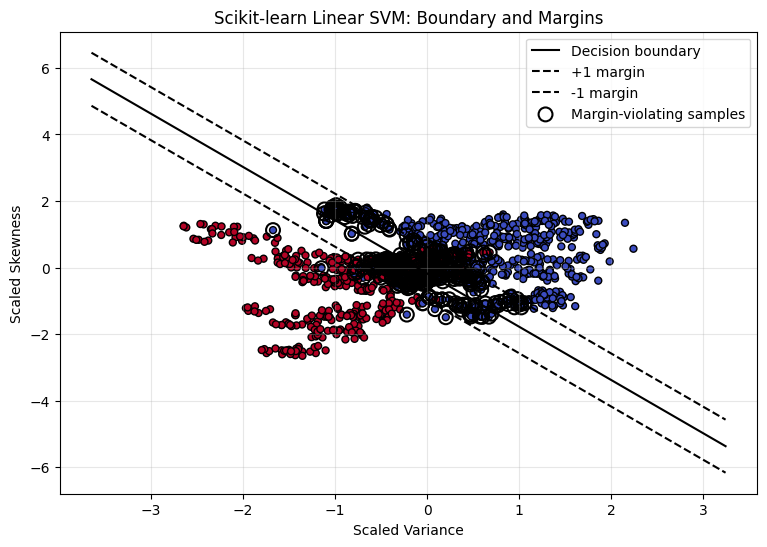

In [18]:
sklearn_svm = SVC(
    kernel="linear",
    C=1.0
)

start_time = time.perf_counter()
sklearn_svm.fit(X_train_svm_scaled, y_train_svm_signed)
sklearn_svm_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_svm_predictions = sklearn_svm.predict(X_test_svm_scaled)
sklearn_svm_prediction_time = time.perf_counter() - start_time

print("Scikit-learn Linear SVM")
print("Accuracy:", accuracy_score(y_test_svm_signed, sklearn_svm_predictions))
print("Precision:", precision_score(y_test_svm_signed, sklearn_svm_predictions, pos_label=1, zero_division=0))
print("Recall:", recall_score(y_test_svm_signed, sklearn_svm_predictions, pos_label=1, zero_division=0))
print("F1-score:", f1_score(y_test_svm_signed, sklearn_svm_predictions, pos_label=1, zero_division=0))
print("Training time:", sklearn_svm_train_time)
print("Prediction time:", sklearn_svm_prediction_time)

plot_svm_boundary(
    type("LinearSVMPlotAdapter", (), {
        "w": sklearn_svm.coef_[0],
        "b": sklearn_svm.intercept_[0],
        "decision_function": sklearn_svm.decision_function
    })(),
    X_train_svm_scaled,
    y_train_svm_signed,
    "Scikit-learn Linear SVM: Boundary and Margins",
    show_violations=True
)

In [19]:
svm_c_results = []

for c_value in [0.01, 0.1, 1, 10, 100]:
    model = ManualLinearSVM(
        C=c_value,
        learning_rate=0.001,
        n_iterations=5000
    )

    start = time.perf_counter()
    model.fit(X_train_svm_scaled, y_train_svm_signed)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_svm_scaled)

    svm_c_results.append({
        "C": c_value,
        "Accuracy": accuracy_score(y_test_svm_signed, predictions),
        "Precision": precision_score(y_test_svm_signed, predictions, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test_svm_signed, predictions, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test_svm_signed, predictions, pos_label=1, zero_division=0),
        "Training Time (s)": train_time
    })

display(pd.DataFrame(svm_c_results).round(4))

,C,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,0.01,0.8582,0.9770,0.6967,0.8134,0.9586
1,0.10,0.8582,0.9770,0.6967,0.8134,1.1966
2,1.00,0.8655,0.9126,0.7705,0.8356,1.8201
3,10.00,0.8873,0.8957,0.8443,0.8692,1.5088
4,100.00,0.8836,0.8750,0.8607,0.8678,1.8174


In [20]:
svm_training_results = []

for learning_rate in [0.0001, 0.001, 0.01]:
    for iterations in [100, 1000, 5000]:
        model = ManualLinearSVM(
            C=1.0,
            learning_rate=learning_rate,
            n_iterations=iterations
        )

        start = time.perf_counter()
        model.fit(X_train_svm_scaled, y_train_svm_signed)
        train_time = time.perf_counter() - start

        predictions = model.predict(X_test_svm_scaled)

        svm_training_results.append({
            "Learning Rate": learning_rate,
            "Iterations": iterations,
            "Accuracy": accuracy_score(y_test_svm_signed, predictions),
            "F1-score": f1_score(y_test_svm_signed, predictions, pos_label=1, zero_division=0),
            "Training Time (s)": train_time,
            "Final Loss": model.loss_history[-1]
        })

display(pd.DataFrame(svm_training_results).round(4))

,Learning Rate,Iterations,Accuracy,F1-score,Training Time (s),Final Loss
0,0.0001,100,0.8764,0.8607,0.0476,0.9929
1,0.0001,1000,0.8836,0.8678,0.4266,0.9349
2,0.0001,5000,0.8909,0.8750,1.8290,0.7710
3,0.0010,100,0.8836,0.8678,0.0437,0.9348
4,0.0010,1000,0.8873,0.8692,0.3915,0.7020
5,0.0010,5000,0.8655,0.8356,2.2163,0.6869
6,0.0100,100,0.8873,0.8692,0.0463,0.7018
7,0.0100,1000,0.8655,0.8341,0.4514,0.6868
8,0.0100,5000,0.8655,0.8341,1.8716,0.6868


## Part C - Kernel SVM and Nonlinear Boundaries

In [21]:
from sklearn.datasets import make_moons

# Generate a nonlinear two-dimensional dataset
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

# Split the data consistently
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.20,
    random_state=42,
    stratify=y_moons
)

print("Training samples:", X_moons_train.shape[0])
print("Testing samples:", X_moons_test.shape[0])

Training samples: 400
Testing samples: 100


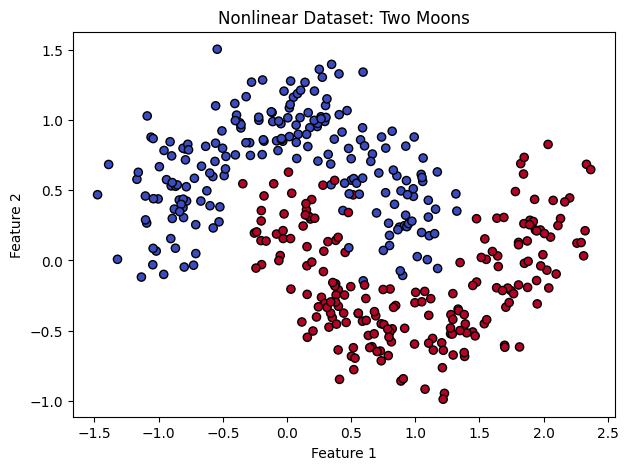

In [22]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons_train[:, 0],
    X_moons_train[:, 1],
    c=y_moons_train,
    cmap="coolwarm",
    edgecolors="black",
    s=35
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: Two Moons")
plt.show()

In [23]:
kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = []

for name, model in kernel_models.items():
    start = time.perf_counter()
    model.fit(X_moons_train, y_moons_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_moons_test)
    prediction_time = time.perf_counter() - start

    kernel_results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(y_moons_test, predictions, zero_division=0),
        "Recall": recall_score(y_moons_test, predictions, zero_division=0),
        "F1-score": f1_score(y_moons_test, predictions, zero_division=0),
        "Training Time (s)": train_time,
        "Prediction Time (s)": prediction_time
    })

display(pd.DataFrame(kernel_results).round(4))

,Kernel,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Linear,0.86,0.8462,0.88,0.8627,0.0088,0.0028
1,Polynomial,0.89,0.8305,0.98,0.8991,0.0092,0.0046
2,RBF,0.99,1.0000,0.98,0.9899,0.0057,0.0014


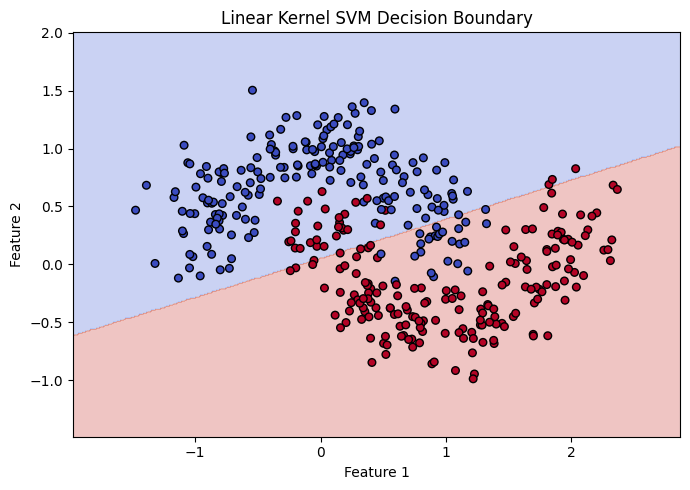

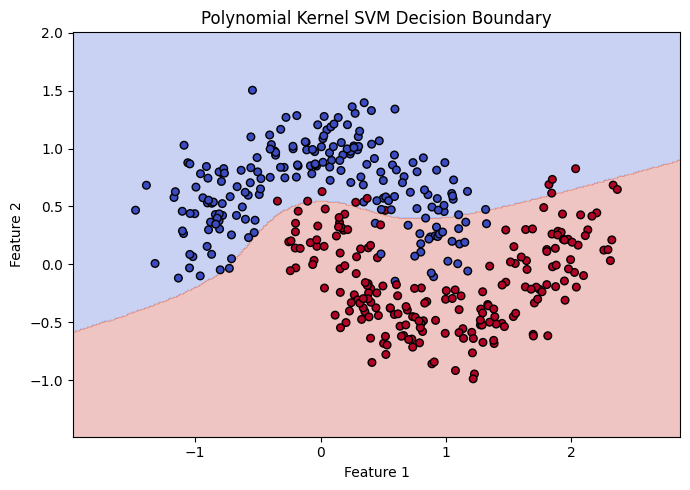

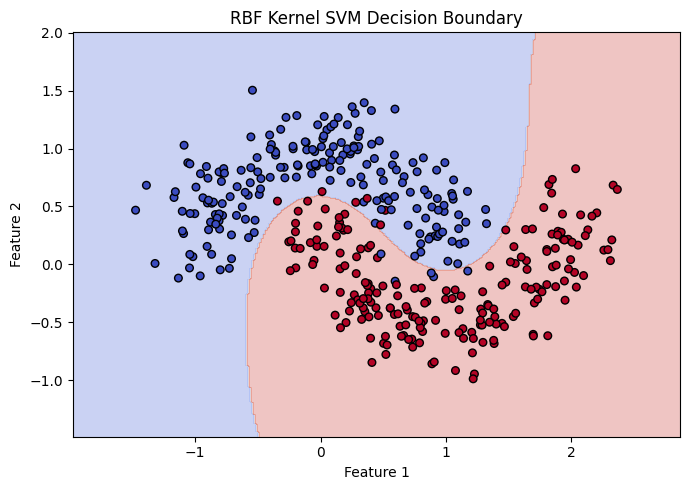

In [24]:
def plot_kernel_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, predictions, alpha=0.3, cmap="coolwarm")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black",
        s=30
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.tight_layout()
    plt.show()


for name, model in kernel_models.items():
    plot_kernel_boundary(
        model,
        X_moons_train,
        y_moons_train,
        f"{name} Kernel SVM Decision Boundary"
    )

Linear: the boundary is straight and may misclassify points along the curved edges.

Polynomial: the boundary can curve, depending on its degree and parameters.

RBF: the boundary can adapt to more complex shapes and may perform better on the two-moons dataset.

### Part C: Observations

1. The make_moons dataset contains two nonlinear classes.
2. The linear kernel learns a straight decision boundary, which may not capture the curved structure effectively.
3. The polynomial kernel can learn nonlinear boundaries by using polynomial feature interactions.
4. The RBF kernel can model more flexible nonlinear boundaries.
5. Accuracy and F1-score help compare how well the kernels classify unseen test samples.
6. Kernel choice affects decision-boundary complexity, training time, and generalization performance.

## Part D - Final Comparison

In [25]:
# Select all four input features
X = df[["variance", "skewness", "curtosis", "entropy"]].values
y = df["class"].values

# Create the consistent 80:20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Store the full-feature datasets
X_train_full = X_train.copy()
X_test_full = X_test.copy()

y_train_full = y_train.copy()
y_test_full = y_test.copy()

print("Training features:", X_train_full.shape)
print("Testing features:", X_test_full.shape)
print("Number of features:", X_train_full.shape[1])
print("Training labels:", np.unique(y_train_full))
print("Testing labels:", np.unique(y_test_full))

Training features: (1097, 4)
Testing features: (275, 4)
Number of features: 4
Training labels: [0 1]
Testing labels: [0 1]


In [26]:
# Scale using training-set statistics only
final_scaler = StandardScaler()

X_train_full_scaled = final_scaler.fit_transform(X_train_full)
X_test_full_scaled = final_scaler.transform(X_test_full)

# Convert class labels from 0/1 to -1/+1 for the manual SVM
y_train_full_signed = np.where(y_train_full == 1, 1, -1)
y_test_full_signed = np.where(y_test_full == 1, 1, -1)

print("Scaled training shape:", X_train_full_scaled.shape)
print("Scaled testing shape:", X_test_full_scaled.shape)

Scaled training shape: (1097, 4)
Scaled testing shape: (275, 4)


In [27]:
final_models = {}
final_results = []

# 1. Manual Decision Tree
model = ManualDecisionTree(
    criterion="gini",
    max_depth=5
)

start = time.perf_counter()
model.fit(X_train_full, y_train_full)
train_time = time.perf_counter() - start

start = time.perf_counter()
predictions = model.predict(X_test_full)
prediction_time = time.perf_counter() - start

final_models["Manual Decision Tree"] = model
final_results.append({
    "Model": "Manual Decision Tree",
    "Accuracy": accuracy_score(y_test_full, predictions),
    "Precision": precision_score(y_test_full, predictions, zero_division=0),
    "Recall": recall_score(y_test_full, predictions, zero_division=0),
    "F1-score": f1_score(y_test_full, predictions, zero_division=0),
    "Training Time (s)": train_time,
    "Prediction Time (s)": prediction_time
})


# 2. Scikit-learn Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start = time.perf_counter()
model.fit(X_train_full, y_train_full)
train_time = time.perf_counter() - start

start = time.perf_counter()
predictions = model.predict(X_test_full)
prediction_time = time.perf_counter() - start

final_models["Scikit-learn Decision Tree"] = model
final_results.append({
    "Model": "Scikit-learn Decision Tree",
    "Accuracy": accuracy_score(y_test_full, predictions),
    "Precision": precision_score(y_test_full, predictions, zero_division=0),
    "Recall": recall_score(y_test_full, predictions, zero_division=0),
    "F1-score": f1_score(y_test_full, predictions, zero_division=0),
    "Training Time (s)": train_time,
    "Prediction Time (s)": prediction_time
})


# 3. Manual Linear SVM
model = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

start = time.perf_counter()
model.fit(X_train_full_scaled, y_train_full_signed)
train_time = time.perf_counter() - start

start = time.perf_counter()
predictions_signed = model.predict(X_test_full_scaled)
prediction_time = time.perf_counter() - start

# Convert predictions back to original 0/1 labels for evaluation
predictions = np.where(predictions_signed == 1, 1, 0)

final_models["Manual Linear SVM"] = model
final_results.append({
    "Model": "Manual Linear SVM",
    "Accuracy": accuracy_score(y_test_full, predictions),
    "Precision": precision_score(y_test_full, predictions, zero_division=0),
    "Recall": recall_score(y_test_full, predictions, zero_division=0),
    "F1-score": f1_score(y_test_full, predictions, zero_division=0),
    "Training Time (s)": train_time,
    "Prediction Time (s)": prediction_time
})


# 4. Scikit-learn Linear SVM
model = SVC(
    kernel="linear",
    C=1.0
)

start = time.perf_counter()
model.fit(X_train_full_scaled, y_train_full_signed)
train_time = time.perf_counter() - start

start = time.perf_counter()
predictions_signed = model.predict(X_test_full_scaled)
prediction_time = time.perf_counter() - start

predictions = np.where(predictions_signed == 1, 1, 0)

final_models["Scikit-learn Linear SVM"] = model
final_results.append({
    "Model": "Scikit-learn Linear SVM",
    "Accuracy": accuracy_score(y_test_full, predictions),
    "Precision": precision_score(y_test_full, predictions, zero_division=0),
    "Recall": recall_score(y_test_full, predictions, zero_division=0),
    "F1-score": f1_score(y_test_full, predictions, zero_division=0),
    "Training Time (s)": train_time,
    "Prediction Time (s)": prediction_time
})


# 5. Scikit-learn RBF SVM
model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

start = time.perf_counter()
model.fit(X_train_full_scaled, y_train_full_signed)
train_time = time.perf_counter() - start

start = time.perf_counter()
predictions_signed = model.predict(X_test_full_scaled)
prediction_time = time.perf_counter() - start

predictions = np.where(predictions_signed == 1, 1, 0)

final_models["Scikit-learn RBF SVM"] = model
final_results.append({
    "Model": "Scikit-learn RBF SVM",
    "Accuracy": accuracy_score(y_test_full, predictions),
    "Precision": precision_score(y_test_full, predictions, zero_division=0),
    "Recall": recall_score(y_test_full, predictions, zero_division=0),
    "F1-score": f1_score(y_test_full, predictions, zero_division=0),
    "Training Time (s)": train_time,
    "Prediction Time (s)": prediction_time
})

print("All five models trained successfully.")

All five models trained successfully.


In [28]:
final_results_df = pd.DataFrame(final_results)

display(
    final_results_df
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0155,0.0098
1,Manual Decision Tree,0.9927,0.9839,1.0000,0.9919,4.2471,0.0007
2,Scikit-learn Decision Tree,0.9927,0.9839,1.0000,0.9919,0.0112,0.0011
3,Scikit-learn Linear SVM,0.9745,0.9457,1.0000,0.9721,0.0221,0.0036
4,Manual Linear SVM,0.8800,0.9238,0.7951,0.8546,2.0587,0.0006


In [29]:
final_results_df.to_csv(
    "part_d_final_comparison.csv",
    index=False
)

print("Saved final comparison to part_d_final_comparison.csv")

Saved final comparison to part_d_final_comparison.csv


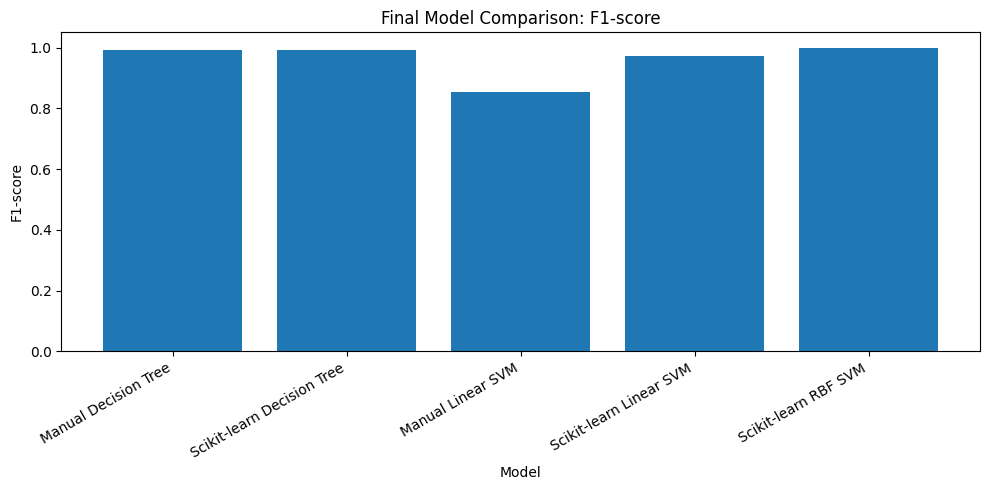

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(
    final_results_df["Model"],
    final_results_df["F1-score"]
)

plt.ylabel("F1-score")
plt.xlabel("Model")
plt.title("Final Model Comparison: F1-score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [31]:
best_f1_model = final_results_df.loc[
    final_results_df["F1-score"].idxmax()
]

fastest_model = final_results_df.loc[
    final_results_df["Training Time (s)"].idxmin()
]

print("Model with highest F1-score:")
print(best_f1_model[["Model", "Accuracy", "Precision", "Recall", "F1-score"]])

print("\nModel with shortest training time:")
print(fastest_model[["Model", "Training Time (s)"]])

Model with highest F1-score:
Model        Scikit-learn RBF SVM
Accuracy                      1.0
Precision                     1.0
Recall                        1.0
F1-score                      1.0
Name: 4, dtype: object

Model with shortest training time:
Model                Scikit-learn Decision Tree
Training Time (s)                      0.011223
Name: 1, dtype: object


## Part D: Final Comparison and Discussion

### 1. Interpretability
Decision Trees are easier to interpret because their predictions can be explained through feature-based rules. SVMs are generally less intuitive, especially when using nonlinear kernels such as RBF.

### 2. Feature Scaling
Decision Trees generally do not require feature scaling because their splits depend on feature thresholds. SVMs are sensitive to feature scales, so standardization is important.

### 3. Overfitting
A very deep Decision Tree can memorize training examples and perform poorly on unseen data. Limiting the tree depth helps control complexity. SVM regularization parameter C also affects the trade-off between margin size and training errors.

### 4. Model Complexity
Decision Trees learn a sequence of feature-based splits. A linear SVM learns a linear separating hyperplane, while an RBF SVM can learn nonlinear decision boundaries. More flexible models may capture complex patterns but can require additional tuning.

### 5. Performance Comparison
The five models were evaluated using the same train-test split. Accuracy, precision, recall, F1-score, training time, and prediction time were recorded. The results show how model choice affects predictive performance and computational cost.

### Conclusion
This assignment demonstrated how Decision Trees and linear SVMs can be implemented from scratch and compared with Scikit-learn. The kernel experiment showed how nonlinear SVMs can model curved decision boundaries. The final comparison used all four Banknote features to evaluate the models consistently.